# Lab 6
---
### Name: Mohammed Feras Sawab

### ID: 2240009066
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from scipy.signal import convolve2d
from skimage import data
from skimage.transform import resize

## Task 1: Filtering in the Frequency Domain (Laplacian)

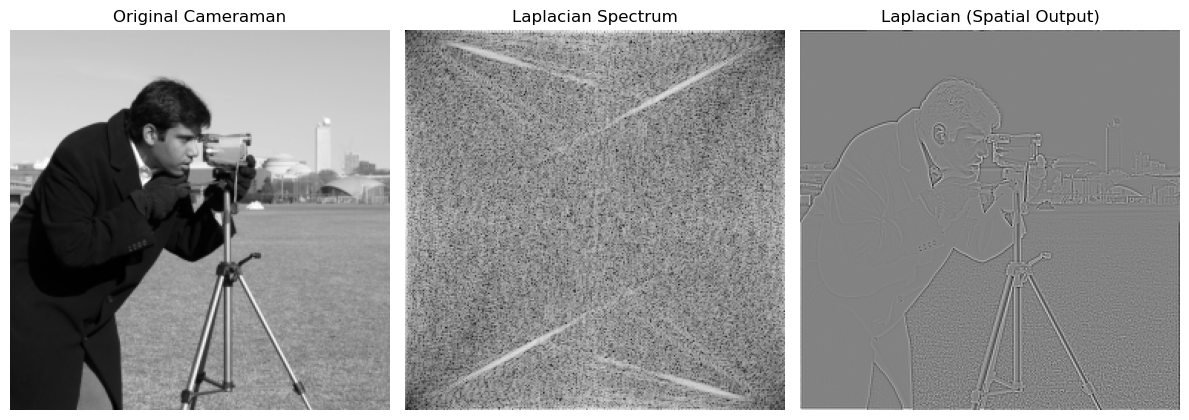

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

## Assessment

Task#1: Using the same Cameraman image, apply the Sobel filter(s) in the frequency domain and show the results.

In [3]:
# Load and resize image
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters (use the provided function)
Sx = center_embed_kernel(sobel_x, (M, N))
Sy = center_embed_kernel(sobel_y, (M, N))

# Multiply in the frequency domain
Gx_freq = F * Sx
Gy_freq = F * Sy

# Back to the spatial domain
gx = ifft2(Gx_freq).real
gy = ifft2(Gy_freq).real
magnitude = np.hypot(gx, gy)

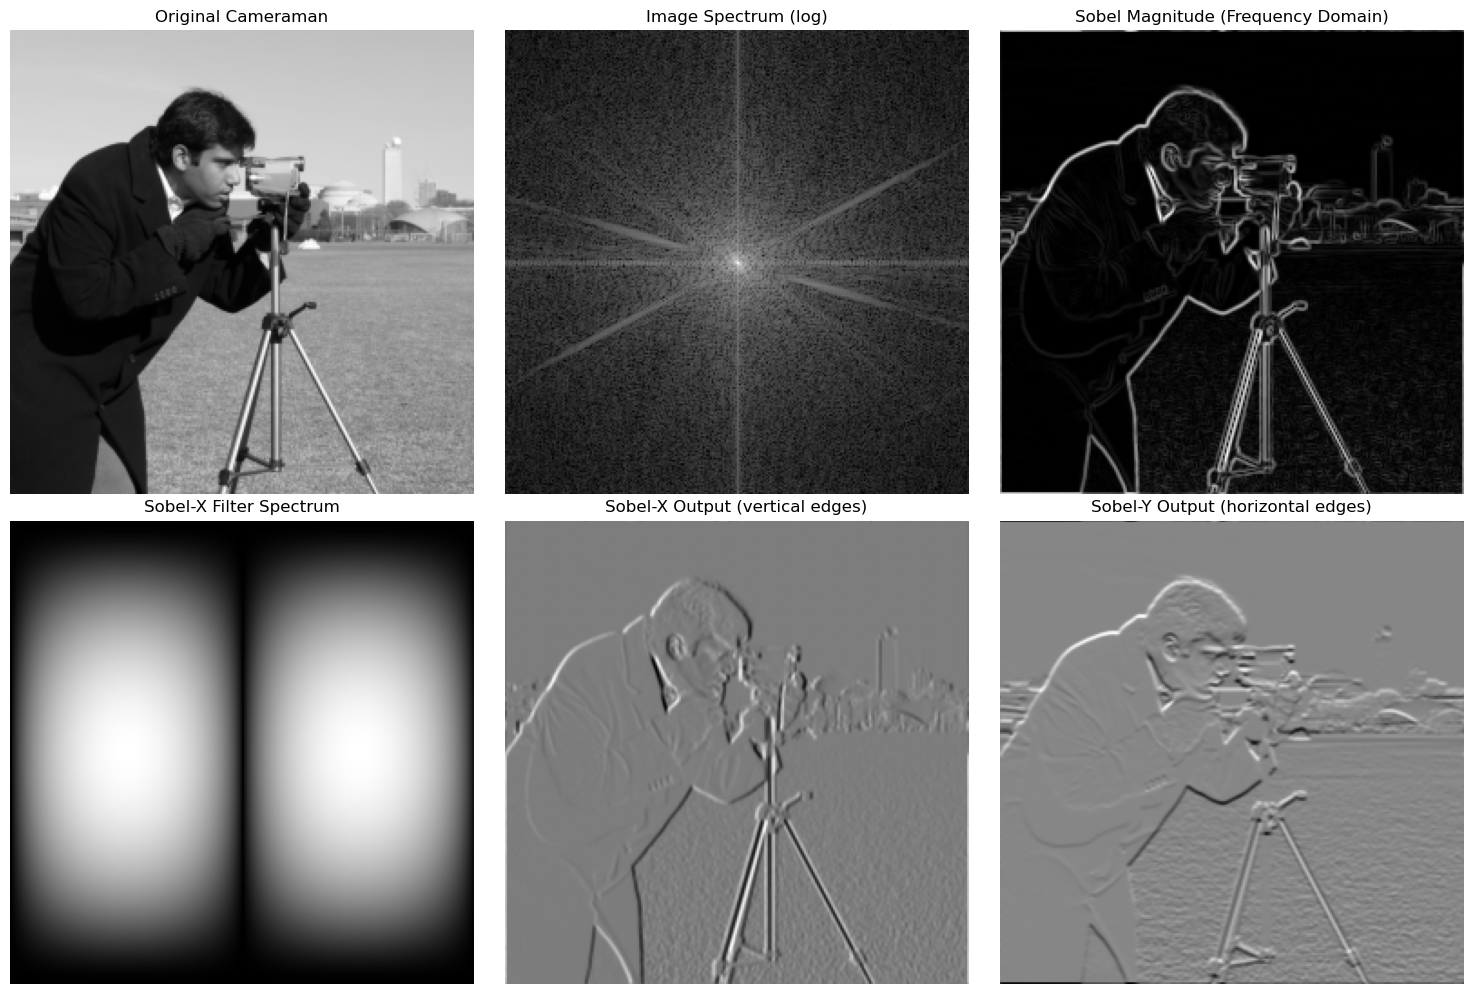

In [4]:
# Plot
panels = [
    (image, 'Original Cameraman'),
    (np.log(1 + np.abs(fftshift(F))), 'Image Spectrum (log)'),
    (magnitude, 'Sobel Magnitude (Frequency Domain)'),
    (np.log(1 + np.abs(fftshift(Sx))), 'Sobel-X Filter Spectrum'),
    (gx, 'Sobel-X Output (vertical edges)'),
    (gy, 'Sobel-Y Output (horizontal edges)'),
]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for a, (img, title) in zip(ax.ravel(), panels):
    a.imshow(img, cmap='gray')
    a.set_title(title)
    a.axis('off')
plt.tight_layout()
plt.show()

### Verification against spatial-domain Sobel

Multiplying in the frequency domain is a (circular) *convolution*, so the result should match `convolve2d` with wrap-around boundaries.

In [5]:
gx_spatial = convolve2d(image, sobel_x, mode='same', boundary='wrap')
gy_spatial = convolve2d(image, sobel_y, mode='same', boundary='wrap')

print('Max |difference| Sobel-X:', np.abs(gx - gx_spatial).max())
print('Max |difference| Sobel-Y:', np.abs(gy - gy_spatial).max())

Max |difference| Sobel-X: 1.7763568394002505e-15
Max |difference| Sobel-Y: 2.8380076066980564e-15
